In [1]:
import pandas as pd
import os

Understanding the data

In [2]:
transactions = pd.read_csv('train_transaction.csv', nrows=5)
identity = pd.read_csv('train_identity.csv', nrows=5)

print("TRANSACTION DATA")
print("================")
print("Shape of sample:", transactions.shape)
print("Columns:")
print(transactions.columns.tolist())

print("\nIDENTITY DATA")
print("=============")
print("Shape of sample:", identity.shape)
print("Columns:")
print(identity.columns.tolist())

TRANSACTION DATA
Shape of sample: (5, 394)
Columns:
['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74',

In [3]:
# --------------------------------------------------
# 1. Load transaction data
# --------------------------------------------------

train_transaction = pd.read_csv('train_transaction.csv')

print()

# --------------------------------------------------
# 2. Basic information
# --------------------------------------------------

print("TRANSACTION DATA")
print("================")

print("Number of rows:", len(train_transaction))
print("Number of columns:", len(train_transaction.columns))

print()

# --------------------------------------------------
# 3. Target distribution
# --------------------------------------------------

print("TARGET DISTRIBUTION")
print("===================")

print(train_transaction["isFraud"].value_counts())

print()

print("TARGET PROPORTION")
print("==================")

print(train_transaction["isFraud"].value_counts(normalize=True))

print()

# --------------------------------------------------
# 4. Memory usage
# --------------------------------------------------

memory_mb = train_transaction.memory_usage(deep=True).sum() / (1024 ** 2)

print("MEMORY USAGE")
print("============")
print(f"{memory_mb:.2f} MB")


TRANSACTION DATA
Number of rows: 590540
Number of columns: 394

TARGET DISTRIBUTION
isFraud
0    569877
1     20663
Name: count, dtype: int64

TARGET PROPORTION
isFraud
0    0.96501
1    0.03499
Name: proportion, dtype: float64

MEMORY USAGE
2062.07 MB


In [4]:
# --------------------------------------------------
# Step 2.2 — Missing-value analysis
# --------------------------------------------------

missing_count = train_transaction.isnull().sum()

missing_percentage = (
    train_transaction.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percentage": missing_percentage
})

# Sort from most missing to least missing
missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

print("TOP 30 FEATURES WITH MOST MISSING VALUES")
print("=========================================")

print(missing_summary.head(30))

print()

# --------------------------------------------------
# How many columns exceed different missingness
# thresholds?
# --------------------------------------------------

print("MISSINGNESS SUMMARY")
print("===================")

print(
    "Columns with > 90% missing:",
    (missing_percentage > 90).sum()
)

print(
    "Columns with > 75% missing:",
    (missing_percentage > 75).sum()
)

print(
    "Columns with > 50% missing:",
    (missing_percentage > 50).sum()
)

print(
    "Columns with > 25% missing:",
    (missing_percentage > 25).sum()
)

print(
    "Columns with no missing values:",
    (missing_percentage == 0).sum()
)

TOP 30 FEATURES WITH MOST MISSING VALUES
       missing_count  missing_percentage
dist2         552913           93.628374
D7            551623           93.409930
D13           528588           89.509263
D14           528353           89.469469
D12           525823           89.041047
D6            517353           87.606767
D9            515614           87.312290
D8            515614           87.312290
V153          508595           86.123717
V149          508595           86.123717
V141          508595           86.123717
V146          508595           86.123717
V154          508595           86.123717
V162          508595           86.123717
V142          508595           86.123717
V158          508595           86.123717
V161          508595           86.123717
V157          508595           86.123717
V138          508595           86.123717
V139          508595           86.123717
V148          508595           86.123717
V140          508595           86.123717
V155          50

In [5]:
# --------------------------------------------------
# Step 2.3 — Data types
# --------------------------------------------------

print("DATA TYPES")
print("==========")

print(train_transaction.dtypes.value_counts())

print()

print("COLUMNS BY DATA TYPE")
print("====================")

for dtype in train_transaction.dtypes.unique():
    columns = train_transaction.columns[
        train_transaction.dtypes == dtype
    ]

    print(f"\n{dtype}: {len(columns)} columns")
    print(columns.tolist())

DATA TYPES
float64    376
str         14
int64        4
Name: count, dtype: int64

COLUMNS BY DATA TYPE

int64: 4 columns
['TransactionID', 'isFraud', 'TransactionDT', 'card1']

float64: 376 columns
['TransactionAmt', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'dist2', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78

In [6]:
# --------------------------------------------------
# Step 2.3b — Categorical feature cardinality
# --------------------------------------------------

categorical_columns = train_transaction.select_dtypes(
    include=["object", "string"]
).columns

print("CATEGORICAL FEATURES")
print("====================")

for column in categorical_columns:
    unique_count = train_transaction[column].nunique(dropna=True)
    missing_count = train_transaction[column].isna().sum()

    print(
        f"{column:15} "
        f"unique values: {unique_count:5} | "
        f"missing: {missing_count:7}"
    )

CATEGORICAL FEATURES
ProductCD       unique values:     5 | missing:       0
card4           unique values:     4 | missing:    1577
card6           unique values:     4 | missing:    1571
P_emaildomain   unique values:    59 | missing:   94456
R_emaildomain   unique values:    60 | missing:  453249
M1              unique values:     2 | missing:  271100
M2              unique values:     2 | missing:  271100
M3              unique values:     2 | missing:  271100
M4              unique values:     3 | missing:  281444
M5              unique values:     2 | missing:  350482
M6              unique values:     2 | missing:  169360
M7              unique values:     2 | missing:  346265
M8              unique values:     2 | missing:  346252
M9              unique values:     2 | missing:  346252


In [7]:
# --------------------------------------------------
# Numeric-looking categorical features
# --------------------------------------------------

possible_categorical = [
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2"
]

print("\nNUMERIC-LOOKING CATEGORICAL FEATURES")
print("=====================================")

for column in possible_categorical:
    unique_count = train_transaction[column].nunique(dropna=True)
    missing_count = train_transaction[column].isna().sum()

    print(
        f"{column:15} "
        f"unique values: {unique_count:5} | "
        f"missing: {missing_count:7}"
    )


NUMERIC-LOOKING CATEGORICAL FEATURES
card1           unique values: 13553 | missing:       0
card2           unique values:   500 | missing:    8933
card3           unique values:   114 | missing:    1565
card5           unique values:   119 | missing:    4259
addr1           unique values:   332 | missing:   65706
addr2           unique values:    74 | missing:   65706


In [8]:
# --------------------------------------------------
# Step 2.4 — Transaction amount by fraud status
# --------------------------------------------------

print("TRANSACTION AMOUNT BY FRAUD STATUS")
print("==================================")

amount_summary = train_transaction.groupby("isFraud")["TransactionAmt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(amount_summary)

TRANSACTION AMOUNT BY FRAUD STATUS
          count        mean  median         std    min        max
isFraud                                                          
0        569877  134.511665    68.5  239.395078  0.251  31937.391
1         20663  149.244779    75.0  232.212163  0.292   5191.000


In [9]:
# --------------------------------------------------
# Transaction amount percentiles
# --------------------------------------------------

print("\nTRANSACTION AMOUNT PERCENTILES")
print("==============================")

for fraud_status in [0, 1]:

    data = train_transaction.loc[
        train_transaction["isFraud"] == fraud_status,
        "TransactionAmt"
    ]

    print(f"\n{'Fraud' if fraud_status == 1 else 'Legitimate'}:")

    print(
        data.quantile(
            [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )


TRANSACTION AMOUNT PERCENTILES

Legitimate:
0.25      43.970
0.50      68.500
0.75     120.000
0.90     267.112
0.95     435.000
0.99    1104.000
Name: TransactionAmt, dtype: float64

Fraud:
0.25     35.044
0.50     75.000
0.75    161.000
0.90    335.000
0.95    500.000
0.99    994.000
Name: TransactionAmt, dtype: float64


In [10]:
# --------------------------------------------------
# Step 2.4 — Time-based fraud analysis
# --------------------------------------------------

# Convert TransactionDT from seconds into hours
train_transaction["TransactionHour"] = (
    train_transaction["TransactionDT"] // 3600
)

# Extract hour within the day
train_transaction["HourOfDay"] = (
    train_transaction["TransactionHour"] % 24
)

# Calculate fraud rate by hour
hourly_fraud = train_transaction.groupby("HourOfDay")["isFraud"].agg(
    ["count", "sum", "mean"]
)

# Convert fraud rate to percentage
hourly_fraud["fraud_rate_percent"] = hourly_fraud["mean"] * 100

print("FRAUD RATE BY HOUR")
print("==================")

print(
    hourly_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY HOUR
           count   sum  fraud_rate_percent
HourOfDay                                 
0          37795  1186               3.138
1          32797  1027               3.131
2          26732  1002               3.748
3          20802   797               3.831
4          14839   770               5.189
5           9701   682               7.030
6           6007   467               7.774
7           3704   393              10.610
8           2591   241               9.301
9           2479   223               8.996
10          3627   193               5.321
11          6827   265               3.882
12         12451   379               3.044
13         20315   465               2.289
14         28328   686               2.422
15         33859   860               2.540
16         38698  1142               2.951
17         40723  1284               3.153
18         41639  1467               3.523
19         42115  1463               3.474
20         41782  1432             

C:\Users\uthay\AppData\Local\Temp\ipykernel_33536\1732822977.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_transaction["TransactionHour"] = (
C:\Users\uthay\AppData\Local\Temp\ipykernel_33536\1732822977.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_transaction["HourOfDay"] = (


In [11]:
# --------------------------------------------------
# Step 2.4 — Fraud rate by ProductCD
# --------------------------------------------------

product_fraud = train_transaction.groupby("ProductCD")["isFraud"].agg(
    ["count", "sum", "mean"]
)

product_fraud["fraud_rate_percent"] = (
    product_fraud["mean"] * 100
)

print("FRAUD RATE BY PRODUCT")
print("=====================")

print(
    product_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY PRODUCT
            count   sum  fraud_rate_percent
ProductCD                                  
C           68519  8008              11.687
H           33024  1574               4.766
R           37699  1426               3.783
S           11628   686               5.900
W          439670  8969               2.040


In [12]:
# --------------------------------------------------
# Step 2.4 — Fraud rate by card4
# --------------------------------------------------

card4_fraud = train_transaction.groupby("card4")["isFraud"].agg(
    ["count", "sum", "mean"]
)

card4_fraud["fraud_rate_percent"] = (
    card4_fraud["mean"] * 100
)

print("FRAUD RATE BY CARD4")
print("===================")

print(
    card4_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY CARD4
                   count    sum  fraud_rate_percent
card4                                              
american express    8328    239               2.870
discover            6651    514               7.728
mastercard        189217   6496               3.433
visa              384767  13373               3.476


In [13]:
# --------------------------------------------------
# Step 2.4 — Fraud rate by card6
# --------------------------------------------------

card6_fraud = train_transaction.groupby("card6")["isFraud"].agg(
    ["count", "sum", "mean"]
)

card6_fraud["fraud_rate_percent"] = (
    card6_fraud["mean"] * 100
)

print("FRAUD RATE BY CARD6")
print("===================")

print(
    card6_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY CARD6
                  count    sum  fraud_rate_percent
card6                                             
charge card          15      0               0.000
credit           148986   9950               6.678
debit            439938  10674               2.426
debit or credit      30      0               0.000


In [14]:
# --------------------------------------------------
# Step 2.5 — Fraud rate by P_emaildomain
# --------------------------------------------------

email_fraud = train_transaction.groupby(
    "P_emaildomain"
)["isFraud"].agg(
    ["count", "sum", "mean"]
)

email_fraud["fraud_rate_percent"] = (
    email_fraud["mean"] * 100
)

print("FRAUD RATE BY PURCHASER EMAIL DOMAIN")
print("====================================")

print(
    email_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ]
    .sort_values(
        by="fraud_rate_percent",
        ascending=False
    )
    .round(3)
)

FRAUD RATE BY PURCHASER EMAIL DOMAIN
                   count   sum  fraud_rate_percent
P_emaildomain                                     
protonmail.com        76    31              40.789
mail.com             559   106              18.962
outlook.es           438    57              13.014
aim.com              315    40              12.698
outlook.com         5096   482               9.458
hotmail.es           305    20               6.557
live.com.mx          749    41               5.474
hotmail.com        45250  2396               5.295
gmail.com         228355  9943               4.354
yahoo.fr             143     5               3.497
embarqmail.com       260     9               3.462
mac.com              436    14               3.211
icloud.com          6267   197               3.143
comcast.net         7888   246               3.119
charter.net          816    25               3.064
frontier.com         280     8               2.857
bellsouth.net       1909    53               

In [15]:
# --------------------------------------------------
# Step 2.6 — Fraud rate by R_emaildomain missingness
# --------------------------------------------------

r_email_missing = train_transaction.groupby(
    train_transaction["R_emaildomain"].isna()
)["isFraud"].agg(
    ["count", "sum", "mean"]
)

r_email_missing["fraud_rate_percent"] = (
    r_email_missing["mean"] * 100
)

r_email_missing.index = [
    "R_emaildomain present",
    "R_emaildomain missing"
]

print("FRAUD RATE BY R_EMAILDOMAIN MISSINGNESS")
print("=======================================")

print(
    r_email_missing[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY R_EMAILDOMAIN MISSINGNESS
                        count    sum  fraud_rate_percent
R_emaildomain present  137291  11227               8.178
R_emaildomain missing  453249   9436               2.082


In [16]:
# --------------------------------------------------
# Step 2.7 — Fraud rate by M1 missingness
# --------------------------------------------------

m1_missing = train_transaction.groupby(
    train_transaction["M1"].isna()
)["isFraud"].agg(
    ["count", "sum", "mean"]
)

m1_missing["fraud_rate_percent"] = (
    m1_missing["mean"] * 100
)

m1_missing.index = [
    "M1 present",
    "M1 missing"
]

print("FRAUD RATE BY M1 MISSINGNESS")
print("============================")

print(
    m1_missing[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY M1 MISSINGNESS
             count    sum  fraud_rate_percent
M1 present  319440   6342               1.985
M1 missing  271100  14321               5.283


In [17]:
# --------------------------------------------------
# Step 2.7 — Fraud rate by M-feature missingness
# --------------------------------------------------

m_columns = [
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

print("FRAUD RATE BY M-FEATURE MISSINGNESS")
print("===================================")

for column in m_columns:

    missing_fraud = train_transaction.groupby(
        train_transaction[column].isna()
    )["isFraud"].agg(
        ["count", "sum", "mean"]
    )

    missing_fraud["fraud_rate_percent"] = (
        missing_fraud["mean"] * 100
    )

    print(f"\n{column}")
    print("-" * len(column))

    print(
        missing_fraud[
            ["count", "sum", "fraud_rate_percent"]
        ].round(3)
    )

FRAUD RATE BY M-FEATURE MISSINGNESS

M1
--
        count    sum  fraud_rate_percent
M1                                      
False  319440   6342               1.985
True   271100  14321               5.283

M2
--
        count    sum  fraud_rate_percent
M2                                      
False  319440   6342               1.985
True   271100  14321               5.283

M3
--
        count    sum  fraud_rate_percent
M3                                      
False  319440   6342               1.985
True   271100  14321               5.283

M4
--
        count    sum  fraud_rate_percent
M4                                      
False  309096  15436               4.994
True   281444   5227               1.857

M5
--
        count    sum  fraud_rate_percent
M5                                      
False  240058   7569               3.153
True   350482  13094               3.736

M6
--
        count    sum  fraud_rate_percent
M6                                      
False  421180   8692

In [18]:
identity = pd.read_csv("train_identity.csv")
# --------------------------------------------------
# Step 2.8 — Fraud rate by DeviceType
# --------------------------------------------------

# Merge DeviceType from identity data with transaction data
device_data = train_transaction[
    ["TransactionID", "isFraud"]
].merge(
    identity[
        ["TransactionID", "DeviceType"]
    ],
    on="TransactionID",
    how="left"
)

# Calculate fraud rate by device type
device_fraud = device_data.groupby("DeviceType")["isFraud"].agg(
    ["count", "sum", "mean"]
)

# Convert fraud rate to percentage
device_fraud["fraud_rate_percent"] = (
    device_fraud["mean"] * 100
)

print("FRAUD RATE BY DEVICE TYPE")
print("=========================")

print(
    device_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY DEVICE TYPE
            count   sum  fraud_rate_percent
DeviceType                                 
desktop     85165  5554               6.521
mobile      55645  5657              10.166


In [19]:
# --------------------------------------------------
# Step 2.9 — Fraud rate by identity availability
# --------------------------------------------------

identity_available = train_transaction["TransactionID"].isin(
    identity["TransactionID"]
)

identity_fraud = train_transaction.groupby(
    identity_available
)["isFraud"].agg(
    ["count", "sum", "mean"]
)

identity_fraud["fraud_rate_percent"] = (
    identity_fraud["mean"] * 100
)

identity_fraud.index = [
    "Identity missing",
    "Identity present"
]

print("FRAUD RATE BY IDENTITY AVAILABILITY")
print("===================================")

print(
    identity_fraud[
        ["count", "sum", "fraud_rate_percent"]
    ].round(3)
)

FRAUD RATE BY IDENTITY AVAILABILITY
                   count    sum  fraud_rate_percent
Identity missing  446307   9345               2.094
Identity present  144233  11318               7.847


In [20]:
# --------------------------------------------------
# Step 2.10 — V-feature missingness vs fraud
# --------------------------------------------------

v_columns = [
    column for column in train_transaction.columns
    if column.startswith("V")
]

v_missing_analysis = []

for column in v_columns:

    missing = train_transaction[column].isna()

    fraud_missing = train_transaction.loc[
        missing, "isFraud"
    ]

    fraud_present = train_transaction.loc[
        ~missing, "isFraud"
    ]

    v_missing_analysis.append({
        "feature": column,
        "missing_count": missing.sum(),
        "missing_percent": missing.mean() * 100,
        "fraud_rate_missing": fraud_missing.mean() * 100,
        "fraud_rate_present": fraud_present.mean() * 100,
        "fraud_rate_difference": (
            fraud_missing.mean() -
            fraud_present.mean()
        ) * 100
    })

v_missing_analysis = pd.DataFrame(
    v_missing_analysis
)

# Sort by absolute difference in fraud rate
v_missing_analysis["absolute_difference"] = (
    v_missing_analysis["fraud_rate_difference"].abs()
)

v_missing_analysis = v_missing_analysis.sort_values(
    by="absolute_difference",
    ascending=False
)

print("TOP V FEATURES BY FRAUD-RATE DIFFERENCE")
print("========================================")

print(
    v_missing_analysis[
        [
            "feature",
            "missing_count",
            "missing_percent",
            "fraud_rate_missing",
            "fraud_rate_present",
            "fraud_rate_difference"
        ]
    ]
    .head(20)
    .round(3)
)

TOP V FEATURES BY FRAUD-RATE DIFFERENCE
    feature  missing_count  missing_percent  fraud_rate_missing  \
319    V320             12            0.002              16.667   
318    V319             12            0.002              16.667   
317    V318             12            0.002              16.667   
316    V317             12            0.002              16.667   
315    V316             12            0.002              16.667   
311    V312             12            0.002              16.667   
310    V311             12            0.002              16.667   
309    V310             12            0.002              16.667   
308    V309             12            0.002              16.667   
307    V308             12            0.002              16.667   
306    V307             12            0.002              16.667   
305    V306             12            0.002              16.667   
304    V305             12            0.002              16.667   
303    V304           

In [21]:
# --------------------------------------------------
# Step 2.10b — V-feature missingness
# Filter out extremely rare missingness
# --------------------------------------------------

v_filtered = v_missing_analysis[
    v_missing_analysis["missing_count"] >= 1000
].copy()

v_filtered = v_filtered.sort_values(
    by="absolute_difference",
    ascending=False
)

print("V FEATURES WITH AT LEAST 1,000 MISSING VALUES")
print("==============================================")

print(
    v_filtered[
        [
            "feature",
            "missing_count",
            "missing_percent",
            "fraud_rate_missing",
            "fraud_rate_present",
            "fraud_rate_difference"
        ]
    ]
    .head(20)
    .round(3)
)

V FEATURES WITH AT LEAST 1,000 MISSING VALUES
    feature  missing_count  missing_percent  fraud_rate_missing  \
199    V200         450721           76.324               2.128   
200    V201         450721           76.324               2.128   
170    V171         450721           76.324               2.128   
168    V169         450721           76.324               2.128   
174    V175         450721           76.324               2.128   
207    V208         450721           76.324               2.128   
208    V209         450721           76.324               2.128   
209    V210         450721           76.324               2.128   
169    V170         450721           76.324               2.128   
197    V198         450721           76.324               2.128   
188    V189         450721           76.324               2.128   
187    V188         450721           76.324               2.128   
183    V184         450721           76.324               2.128   
184    V185     

In [22]:
# --------------------------------------------------
# Step 2.11 — V-feature value differences
# --------------------------------------------------

v_columns = [
    column for column in train_transaction.columns
    if column.startswith("V")
]

v_value_analysis = []

for column in v_columns:

    legitimate = train_transaction.loc[
        train_transaction["isFraud"] == 0,
        column
    ].dropna()

    fraud = train_transaction.loc[
        train_transaction["isFraud"] == 1,
        column
    ].dropna()

    # Skip features with insufficient data
    if len(legitimate) < 100 or len(fraud) < 100:
        continue

    v_value_analysis.append({
        "feature": column,

        "legitimate_median": legitimate.median(),
        "fraud_median": fraud.median(),

        "legitimate_mean": legitimate.mean(),
        "fraud_mean": fraud.mean(),

        "legitimate_missing_percent":
            train_transaction.loc[
                train_transaction["isFraud"] == 0,
                column
            ].isna().mean() * 100,

        "fraud_missing_percent":
            train_transaction.loc[
                train_transaction["isFraud"] == 1,
                column
            ].isna().mean() * 100
    })

v_value_analysis = pd.DataFrame(v_value_analysis)

# Calculate relative difference in medians
v_value_analysis["median_difference"] = (
    v_value_analysis["fraud_median"]
    - v_value_analysis["legitimate_median"]
).abs()

v_value_analysis = v_value_analysis.sort_values(
    by="median_difference",
    ascending=False
)

print("TOP V FEATURES BY MEDIAN DIFFERENCE")
print("===================================")

print(
    v_value_analysis[
        [
            "feature",
            "legitimate_median",
            "fraud_median",
            "legitimate_mean",
            "fraud_mean",
            "legitimate_missing_percent",
            "fraud_missing_percent",
            "median_difference"
        ]
    ]
    .head(20)
    .round(3)
)

TOP V FEATURES BY MEDIAN DIFFERENCE
    feature  legitimate_median  fraud_median  legitimate_mean  fraud_mean  \
263    V264                0.0        78.924          195.433     275.094   
264    V265                0.0        62.353          146.872     231.959   
202    V203                0.0        47.585         1131.530     458.578   
262    V263                0.0        44.976          111.837     182.903   
203    V204                0.0        38.012          723.729     258.608   
201    V202                0.0        21.389          468.887     155.958   
273    V274                0.0        20.559          101.465     174.241   
306    V307                0.0        12.809          403.708     545.882   
274    V275                0.0        10.000           83.552     151.988   
217    V218                0.0         2.000            1.533       4.000   
35      V36                1.0         0.000            0.586       0.380   
167    V168                0.0         1

Preprocessing

In [23]:
# --------------------------------------------------
# Phase 3.1 — Load and combine transaction + identity
# --------------------------------------------------

# Load the full identity dataset
train_identity = pd.read_csv("train_identity.csv")

print("TRANSACTION DATA")
print("================")
print("Shape:", train_transaction.shape)

print()

print("IDENTITY DATA")
print("=============")
print("Shape:", train_identity.shape)

# --------------------------------------------------
# Merge identity information into transaction data
# --------------------------------------------------

train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

print()

print("COMBINED DATA")
print("=============")
print("Shape:", train.shape)

TRANSACTION DATA
Shape: (590540, 396)

IDENTITY DATA
Shape: (144233, 41)

COMBINED DATA
Shape: (590540, 436)


In [24]:
# --------------------------------------------------
# Phase 3.2 — Verify merged dataset
# --------------------------------------------------

print("MERGE VERIFICATION")
print("==================")

print("Original transaction rows:", len(train_transaction))
print("Combined rows:", len(train))

print()

print("Original transaction columns:", len(train_transaction.columns))
print("Combined columns:", len(train.columns))

print()

print("Target distribution after merge")
print("===============================")

print(train["isFraud"].value_counts())

print()

print("Duplicate TransactionIDs:")
print(train["TransactionID"].duplicated().sum())

MERGE VERIFICATION
Original transaction rows: 590540
Combined rows: 590540

Original transaction columns: 396
Combined columns: 436

Target distribution after merge
isFraud
0    569877
1     20663
Name: count, dtype: int64

Duplicate TransactionIDs:
0


In [25]:
# --------------------------------------------------
# Phase 3.3 — Train / Validation Split
# --------------------------------------------------

from sklearn.model_selection import train_test_split

# Separate features and target
X = train.drop(columns=["isFraud"])
y = train["isFraud"]

# Stratified 80/20 split
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("TRAIN / VALIDATION SPLIT")
print("========================")

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

print()

print("Training fraud distribution")
print("===========================")

print(y_train.value_counts())

print()

print("Training fraud proportion")
print("===========================")

print(y_train.value_counts(normalize=True))

print()

print("Validation fraud distribution")
print("=============================")

print(y_valid.value_counts())

print()

print("Validation fraud proportion")
print("=============================")

print(y_valid.value_counts(normalize=True))

TRAIN / VALIDATION SPLIT
Training rows: 472432
Validation rows: 118108

Training fraud distribution
isFraud
0    455902
1     16530
Name: count, dtype: int64

Training fraud proportion
isFraud
0    0.965011
1    0.034989
Name: proportion, dtype: float64

Validation fraud distribution
isFraud
0    113975
1      4133
Name: count, dtype: int64

Validation fraud proportion
isFraud
0    0.965007
1    0.034993
Name: proportion, dtype: float64


In [26]:
# --------------------------------------------------
# Phase 3.4 — Identify feature types
# --------------------------------------------------

# Explicit categorical features from our EDA
categorical_features = [
    "ProductCD",
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "M1",
    "M2",
    "M3",
    "M4",
    "M5",
    "M6",
    "M7",
    "M8",
    "M9"
]

# Identity categorical features
identity_categorical = [
    "DeviceType",
    "DeviceInfo"
]

categorical_features += identity_categorical

# Check which of these actually exist
categorical_features = [
    column for column in categorical_features
    if column in X_train.columns
]

print("CATEGORICAL FEATURES")
print("====================")

print("Number of categorical features:", len(categorical_features))

print()

print(categorical_features)

CATEGORICAL FEATURES
Number of categorical features: 22

['ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType', 'DeviceInfo']


In [27]:
numerical_features = [
    column for column in X_train.columns
    if column not in categorical_features
    and column != "TransactionID"
]

print()
print("NUMERICAL FEATURES")
print("==================")

print("Number of numerical features:", len(numerical_features))

print()

print(numerical_features[:30])


NUMERICAL FEATURES
Number of numerical features: 412

['TransactionDT', 'TransactionAmt', 'dist1', 'dist2', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12']


In [28]:
# --------------------------------------------------
# Phase 3.5 — Remove identifier from modeling data
# --------------------------------------------------

X_train = X_train.drop(columns=["TransactionID"])
X_valid = X_valid.drop(columns=["TransactionID"])

print("FEATURE DATA AFTER REMOVING TRANSACTIONID")
print("==========================================")

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

FEATURE DATA AFTER REMOVING TRANSACTIONID
Training shape: (472432, 434)
Validation shape: (118108, 434)

Categorical features: 22
Numerical features: 412


In [29]:
# Remove EDA-only engineered columns for now
eda_columns = [
    "TransactionHour",
    "HourOfDay"
]

X_train = X_train.drop(
    columns=eda_columns,
    errors="ignore"
)

X_valid = X_valid.drop(
    columns=eda_columns,
    errors="ignore"
)

# Update numerical feature list
numerical_features = [
    column for column in numerical_features
    if column not in eda_columns
]

print()
print("FINAL FEATURE COUNTS")
print("====================")

print("Categorical:", len(categorical_features))
print("Numerical:", len(numerical_features))
print("Total:", len(categorical_features) + len(numerical_features))


FINAL FEATURE COUNTS
Categorical: 22
Numerical: 410
Total: 432


In [30]:
# --------------------------------------------------
# Phase 3.6 — Categorical cardinality in training data
# --------------------------------------------------

print("CATEGORICAL CARDINALITY — TRAINING DATA")
print("========================================")

for column in categorical_features:

    unique_count = X_train[column].nunique(
        dropna=True
    )

    missing_count = X_train[column].isna().sum()

    print(
        f"{column:15} "
        f"unique: {unique_count:6} | "
        f"missing: {missing_count:7}"
    )

CATEGORICAL CARDINALITY — TRAINING DATA
ProductCD       unique:      5 | missing:       0
card1           unique:  12821 | missing:       0
card2           unique:    500 | missing:    7147
card3           unique:    113 | missing:    1235
card4           unique:      4 | missing:    1243
card5           unique:    115 | missing:    3397
card6           unique:      4 | missing:    1240
addr1           unique:    304 | missing:   52723
addr2           unique:     69 | missing:   52723
P_emaildomain   unique:     59 | missing:   75591
R_emaildomain   unique:     60 | missing:  362236
M1              unique:      2 | missing:  217120
M2              unique:      2 | missing:  217120
M3              unique:      2 | missing:  217120
M4              unique:      3 | missing:  224903
M5              unique:      2 | missing:  280337
M6              unique:      2 | missing:  135792
M7              unique:      2 | missing:  277327
M8              unique:      2 | missing:  277317
M9        

In [31]:
# --------------------------------------------------
# Phase 3.7 — Frequency encoding
# --------------------------------------------------

high_cardinality_features = [
    "card1",
    "DeviceInfo"
]

frequency_maps = {}

for column in high_cardinality_features:

    # Calculate frequencies using TRAINING DATA ONLY
    frequency = (
        X_train[column]
        .value_counts(normalize=True)
    )

    frequency_maps[column] = frequency

    # Apply mapping to training data
    X_train[column + "_freq"] = (
        X_train[column].map(frequency)
    )

    # Apply same training mapping to validation data
    X_valid[column + "_freq"] = (
        X_valid[column].map(frequency)
    )

    # Remove original high-cardinality column
    X_train = X_train.drop(columns=[column])
    X_valid = X_valid.drop(columns=[column])

print("FREQUENCY ENCODING")
print("==================")

for column in high_cardinality_features:

    print(
        f"{column}: "
        f"{len(frequency_maps[column])} categories encoded"
    )

C:\Users\uthay\AppData\Local\Temp\ipykernel_33536\756217280.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_train[column + "_freq"] = (
C:\Users\uthay\AppData\Local\Temp\ipykernel_33536\756217280.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_valid[column + "_freq"] = (


FREQUENCY ENCODING
card1: 12821 categories encoded
DeviceInfo: 1686 categories encoded


In [32]:
# --------------------------------------------------
# Phase 3.8 — Update feature lists
# --------------------------------------------------

# Remove high-cardinality features from categorical list
categorical_features = [
    column for column in categorical_features
    if column not in high_cardinality_features
]

# Add frequency-encoded versions to numerical features
numerical_features = numerical_features + [
    "card1_freq",
    "DeviceInfo_freq"
]

print("UPDATED FEATURE TYPES")
print("=====================")

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print()

print("Total features:",
      len(categorical_features) + len(numerical_features))

print()

print("Categorical:")
print(categorical_features)

print()

print("Frequency-encoded numerical:")
print(["card1_freq", "DeviceInfo_freq"])

UPDATED FEATURE TYPES
Categorical features: 20
Numerical features: 412

Total features: 432

Categorical:
['ProductCD', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType']

Frequency-encoded numerical:
['card1_freq', 'DeviceInfo_freq']


In [33]:
# --------------------------------------------------
# Phase 3.9 — Preprocessing pipeline
# --------------------------------------------------

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------
# Numerical preprocessing
# --------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# --------------------------------------------------
# Categorical preprocessing
# --------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# --------------------------------------------------
# Combine preprocessing pipelines
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("PREPROCESSING PIPELINE CREATED")
print("==============================")

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

PREPROCESSING PIPELINE CREATED
Numerical features: 412
Categorical features: 20


In [34]:
# --------------------------------------------------
# Phase 3.10 — Fit preprocessing pipeline
# --------------------------------------------------

print("FITTING PREPROCESSOR...")
print("======================")

X_train_processed = preprocessor.fit_transform(X_train)

print("Training transformation complete.")

print()

print("Transforming validation data...")
X_valid_processed = preprocessor.transform(X_valid)

print("Validation transformation complete.")

print()

print("PROCESSED DATA")
print("==============")

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

print()

print("Training matrix type:")
print(type(X_train_processed))

print()

print("Validation matrix type:")
print(type(X_valid_processed))

FITTING PREPROCESSOR...


ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: 'NotFound'

In [35]:
# --------------------------------------------------
# Phase 3.10a — Check numerical features for strings
# --------------------------------------------------

print("NON-NUMERIC COLUMNS IN NUMERICAL FEATURE LIST")
print("==============================================")

non_numeric_features = []

for column in numerical_features:

    if not pd.api.types.is_numeric_dtype(X_train[column]):
        non_numeric_features.append(column)

        print(
            f"{column:15} "
            f"dtype: {X_train[column].dtype}"
        )

print()

print(
    "Total non-numeric columns:",
    len(non_numeric_features)
)

NON-NUMERIC COLUMNS IN NUMERICAL FEATURE LIST
id_12           dtype: str
id_15           dtype: str
id_16           dtype: str
id_23           dtype: str
id_27           dtype: str
id_28           dtype: str
id_29           dtype: str
id_30           dtype: str
id_31           dtype: str
id_33           dtype: str
id_34           dtype: str
id_35           dtype: str
id_36           dtype: str
id_37           dtype: str
id_38           dtype: str

Total non-numeric columns: 15


In [36]:
# --------------------------------------------------
# Phase 3.10b — Identity categorical cardinality
# --------------------------------------------------

identity_categorical = [
    "id_12",
    "id_15",
    "id_16",
    "id_23",
    "id_27",
    "id_28",
    "id_29",
    "id_30",
    "id_31",
    "id_33",
    "id_34",
    "id_35",
    "id_36",
    "id_37",
    "id_38"
]

print("IDENTITY CATEGORICAL FEATURES")
print("=============================")

for column in identity_categorical:

    unique_count = X_train[column].nunique(dropna=True)
    missing_count = X_train[column].isna().sum()

    print(
        f"{column:8} "
        f"unique: {unique_count:5} | "
        f"missing: {missing_count:7}"
    )

IDENTITY CATEGORICAL FEATURES
id_12    unique:     2 | missing:  356774
id_15    unique:     3 | missing:  359347
id_16    unique:     2 | missing:  368768
id_23    unique:     3 | missing:  468306
id_27    unique:     2 | missing:  468306
id_28    unique:     2 | missing:  359353
id_29    unique:     2 | missing:  359353
id_30    unique:    75 | missing:  410249
id_31    unique:   124 | missing:  359907
id_33    unique:   236 | missing:  413642
id_34    unique:     4 | missing:  410062
id_35    unique:     2 | missing:  359347
id_36    unique:     2 | missing:  359347
id_37    unique:     2 | missing:  359347
id_38    unique:     2 | missing:  359347


In [37]:
# --------------------------------------------------
# Phase 3.10c — Correct feature classifications
# --------------------------------------------------

# Move the 15 string-based identity features
# from numerical to categorical

categorical_features = categorical_features + identity_categorical

numerical_features = [
    column
    for column in numerical_features
    if column not in identity_categorical
]

print("CORRECTED FEATURE TYPES")
print("=======================")

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print()

print("Total features:",
      len(categorical_features) + len(numerical_features))

print()

print("Identity categorical features:")
print(identity_categorical)

CORRECTED FEATURE TYPES
Categorical features: 35
Numerical features: 397

Total features: 432

Identity categorical features:
['id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38']


In [38]:
# --------------------------------------------------
# Phase 3.10d — Rebuild preprocessing pipeline
# --------------------------------------------------

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------
# Numerical pipeline
# --------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# --------------------------------------------------
# Categorical pipeline
# --------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# --------------------------------------------------
# Combine pipelines
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("CORRECTED PREPROCESSING PIPELINE")
print("================================")

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total original features:",
      len(numerical_features) + len(categorical_features))

CORRECTED PREPROCESSING PIPELINE
Numerical features: 397
Categorical features: 35
Total original features: 432


In [43]:
# --------------------------------------------------
# Phase 3.10e — Fit and transform
# --------------------------------------------------

print("FITTING PREPROCESSOR...")
print("======================")

X_train_processed = preprocessor.fit_transform(X_train)

print("Training transformation complete.")

print()

print("Transforming validation data...")

X_valid_processed = preprocessor.transform(X_valid)

print("Validation transformation complete.")

print()

print("PROCESSED DATA")
print("==============")

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

print()

print("Training matrix type:")
print(type(X_train_processed))

print()

print("Validation matrix type:")
print(type(X_valid_processed))

FITTING PREPROCESSOR...


TypeError: Encoders require their input argument must be uniformly strings or numbers. Got ['float', 'str']

In [39]:
# --------------------------------------------------
# Phase 3.10f — Fix mixed categorical types
# --------------------------------------------------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.preprocessing import FunctionTransformer

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "to_string",
            FunctionTransformer(
                lambda X: X.astype(str)
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# --------------------------------------------------
# Rebuild complete preprocessor
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("UPDATED PREPROCESSING PIPELINE")
print("===============================")

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print(
    "Total original features:",
    len(numerical_features) + len(categorical_features)
)

UPDATED PREPROCESSING PIPELINE
Numerical features: 397
Categorical features: 35
Total original features: 432


In [40]:
# --------------------------------------------------
# Phase 3.10g — Fit and transform
# --------------------------------------------------

print("FITTING PREPROCESSOR...")
print("======================")

X_train_processed = preprocessor.fit_transform(X_train)

print("Training transformation complete.")

print()

print("Transforming validation data...")

X_valid_processed = preprocessor.transform(X_valid)

print("Validation transformation complete.")

print()

print("PROCESSED DATA")
print("==============")

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

print()

print("Training matrix type:")
print(type(X_train_processed))

print()

print("Validation matrix type:")
print(type(X_valid_processed))

FITTING PREPROCESSOR...
Training transformation complete.

Transforming validation data...
Validation transformation complete.

PROCESSED DATA
Training shape: (472432, 2148)
Validation shape: (118108, 2148)

Training matrix type:
<class 'scipy.sparse._csr.csr_matrix'>

Validation matrix type:
<class 'scipy.sparse._csr.csr_matrix'>


In [41]:
# --------------------------------------------------
# Phase 3.11 — Final preprocessing sanity check
# --------------------------------------------------

import numpy as np

print("FINAL PREPROCESSING SANITY CHECK")
print("================================")

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

print()

print("Training NaN values:",
      np.isnan(X_train_processed.data).sum())

print("Validation NaN values:",
      np.isnan(X_valid_processed.data).sum())

print()

print("Training infinite values:",
      np.isinf(X_train_processed.data).sum())

print("Validation infinite values:",
      np.isinf(X_valid_processed.data).sum())

print()

print("Training non-zero values:",
      X_train_processed.nnz)

print("Validation non-zero values:",
      X_valid_processed.nnz)

FINAL PREPROCESSING SANITY CHECK
Training shape: (472432, 2148)
Validation shape: (118108, 2148)

Training NaN values: 0
Validation NaN values: 0

Training infinite values: 0
Validation infinite values: 0

Training non-zero values: 204090624
Validation non-zero values: 51022581


In [42]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [220]:
print("FITTING LOGISTIC REGRESSION...")
print("============================")

log_reg.fit(X_train_processed, y_train)

print("Logistic Regression training complete.")

FITTING LOGISTIC REGRESSION...
Logistic Regression training complete.


C:\Users\uthay\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [43]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    solver="saga",
    C=0.1,
    class_weight="balanced",
    max_iter=5000,
    tol=1e-3,
    random_state=42
)

print("FITTING LOGISTIC REGRESSION...")
print("============================")

log_reg.fit(X_train_processed, y_train)

print("Logistic Regression training complete.")
print("Iterations used:", log_reg.n_iter_)

FITTING LOGISTIC REGRESSION...
Logistic Regression training complete.
Iterations used: [603]


In [44]:
print("GENERATING VALIDATION PREDICTIONS...")
print("===================================")

y_valid_proba = log_reg.predict_proba(X_valid_processed)[:, 1]
y_valid_pred = log_reg.predict(X_valid_processed)

print("Validation predictions generated.")
print("Probability shape:", y_valid_proba.shape)
print("Prediction shape:", y_valid_pred.shape)

GENERATING VALIDATION PREDICTIONS...
Validation predictions generated.
Probability shape: (118108,)
Prediction shape: (118108,)


In [45]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("LOGISTIC REGRESSION BASELINE")
print("============================")

roc_auc = roc_auc_score(y_valid, y_valid_proba)
pr_auc = average_precision_score(y_valid, y_valid_proba)

precision = precision_score(y_valid, y_valid_pred)
recall = recall_score(y_valid, y_valid_pred)
f1 = f1_score(y_valid, y_valid_pred)

cm = confusion_matrix(y_valid, y_valid_pred)

print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1 Score:   {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

LOGISTIC REGRESSION BASELINE
ROC-AUC:   0.8731
PR-AUC:    0.4473
Precision:  0.1426
Recall:     0.7472
F1 Score:   0.2396

Confusion Matrix:
[[95415 18560]
 [ 1045  3088]]


Logistic Regression
-------------------
Solver:           SAGA
Regularization:   L2 (default)
C:                0.1
Class weighting:  balanced
Max iterations:   5000
Tolerance:        1e-3
Actual iterations:603

Validation
----------
ROC-AUC:           0.8731
PR-AUC:            0.4473
Precision:         0.1426
Recall:            0.7472
F1:                0.2396

In [46]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.7.0


In [47]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

print("FITTING LIGHTGBM...")
print("===================")

lgb_model.fit(
    X_train_processed,
    y_train
)

print("LightGBM training complete.")

FITTING LIGHTGBM...
[LightGBM] [Info] Number of positive: 16530, number of negative: 455902
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.281457 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 39667
[LightGBM] [Info] Number of data points in the train set: 472432, number of used features: 1517
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.034989 -> initscore=-3.317101
[LightGBM] [Info] Start training from score -3.317101
LightGBM training complete.


In [48]:
print("GENERATING LIGHTGBM VALIDATION PREDICTIONS...")
print("==============================================")

y_valid_proba_lgb = lgb_model.predict_proba(X_valid_processed)[:, 1]
y_valid_pred_lgb = lgb_model.predict(X_valid_processed)

print("Validation predictions generated.")
print("Probability shape:", y_valid_proba_lgb.shape)
print("Prediction shape:", y_valid_pred_lgb.shape)

GENERATING LIGHTGBM VALIDATION PREDICTIONS...
Validation predictions generated.
Probability shape: (118108,)
Prediction shape: (118108,)


In [49]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("LIGHTGBM BASELINE")
print("=================")

roc_auc_lgb = roc_auc_score(y_valid, y_valid_proba_lgb)
pr_auc_lgb = average_precision_score(y_valid, y_valid_proba_lgb)

precision_lgb = precision_score(y_valid, y_valid_pred_lgb)
recall_lgb = recall_score(y_valid, y_valid_pred_lgb)
f1_lgb = f1_score(y_valid, y_valid_pred_lgb)

cm_lgb = confusion_matrix(y_valid, y_valid_pred_lgb)

print(f"ROC-AUC:   {roc_auc_lgb:.4f}")
print(f"PR-AUC:    {pr_auc_lgb:.4f}")
print(f"Precision: {precision_lgb:.4f}")
print(f"Recall:    {recall_lgb:.4f}")
print(f"F1 Score:  {f1_lgb:.4f}")

print("\nConfusion Matrix:")
print(cm_lgb)

LIGHTGBM BASELINE
ROC-AUC:   0.9522
PR-AUC:    0.7584
Precision: 0.9307
Recall:    0.5001
F1 Score:  0.6506

Confusion Matrix:
[[113821    154]
 [  2066   2067]]


In [50]:
from sklearn.model_selection import train_test_split

X_tune_train, X_tune_valid, y_tune_train, y_tune_valid = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("TUNING SPLIT")
print("============")
print("Tuning train shape:", X_tune_train.shape)
print("Tuning validation shape:", X_tune_valid.shape)

print("\nFraud cases:")
print("Tuning train:", y_tune_train.sum())
print("Tuning validation:", y_tune_valid.sum())

TUNING SPLIT
Tuning train shape: (377945, 2148)
Tuning validation shape: (94487, 2148)

Fraud cases:
Tuning train: 13224
Tuning validation: 3306


In [51]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

lgb_tuned = LGBMClassifier(
    objective="binary",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1
)

print("FITTING TUNED LIGHTGBM...")
print("=========================")

lgb_tuned.fit(
    X_tune_train,
    y_tune_train,
    eval_set=[(X_tune_valid, y_tune_valid)],
    eval_metric="average_precision",
    callbacks=[
        early_stopping(
            stopping_rounds=100,
            verbose=True
        ),
        log_evaluation(period=100)
    ]
)

print("\nTuned LightGBM training complete.")
print("Best iteration:", lgb_tuned.best_iteration_)

FITTING TUNED LIGHTGBM...


C:\Users\uthay\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 13224, number of negative: 364721
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.159536 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 39210
[LightGBM] [Info] Number of data points in the train set: 377945, number of used features: 1299
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.034989 -> initscore=-3.317099
[LightGBM] [Info] Start training from score -3.317099
Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.597871	valid_0's binary_logloss: 0.0881398
[200]	valid_0's average_precision: 0.648097	valid_0's binary_logloss: 0.0799921
[300]	valid_0's average_precision: 0.67687	valid_0's binary_logloss: 0.0757568
[400]	valid_0's average_precision: 0.69575	valid_0's binary_logloss: 0.073085
[500]	valid_0's average_precision: 0.711207	valid_0's bina

In [52]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
import warnings

warnings.filterwarnings(
    "ignore",
    message="The argument 'eval_set' is deprecated"
)

lgb_tuned = LGBMClassifier(
    objective="binary",
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1
)

print("FITTING TUNED LIGHTGBM...")
print("=========================")

lgb_tuned.fit(
    X_tune_train,
    y_tune_train,
    eval_set=[(X_tune_valid, y_tune_valid)],
    eval_metric="average_precision",
    callbacks=[
        early_stopping(
            stopping_rounds=100,
            verbose=True
        ),
        log_evaluation(period=250)
    ]
)

print("\nTuned LightGBM training complete.")
print("Best iteration:", lgb_tuned.best_iteration_)

FITTING TUNED LIGHTGBM...
[LightGBM] [Info] Number of positive: 13224, number of negative: 364721
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.174443 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 39210
[LightGBM] [Info] Number of data points in the train set: 377945, number of used features: 1299
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.034989 -> initscore=-3.317099
[LightGBM] [Info] Start training from score -3.317099
Training until validation scores don't improve for 100 rounds
[250]	valid_0's average_precision: 0.663867	valid_0's binary_logloss: 0.0776769
[500]	valid_0's average_precision: 0.711207	valid_0's binary_logloss: 0.0708574
[750]	valid_0's average_precision: 0.73757	valid_0's binary_logloss: 0.0668939
[1000]	valid_0's average_precision: 0.754616	valid_0's binary_logloss: 0.06419
[1250]	valid_0's average_precis

In [53]:
print("GENERATING TUNED LIGHTGBM VALIDATION PREDICTIONS...")
print("===================================================")

y_valid_proba_lgb_tuned = lgb_tuned.predict_proba(
    X_valid_processed
)[:, 1]

y_valid_pred_lgb_tuned = lgb_tuned.predict(
    X_valid_processed
)

print("Validation predictions generated.")
print("Probability shape:", y_valid_proba_lgb_tuned.shape)
print("Prediction shape:", y_valid_pred_lgb_tuned.shape)

GENERATING TUNED LIGHTGBM VALIDATION PREDICTIONS...
Validation predictions generated.
Probability shape: (118108,)
Prediction shape: (118108,)


In [54]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("TUNED LIGHTGBM — FINAL VALIDATION")
print("=================================")

roc_auc_lgb_tuned = roc_auc_score(
    y_valid,
    y_valid_proba_lgb_tuned
)

pr_auc_lgb_tuned = average_precision_score(
    y_valid,
    y_valid_proba_lgb_tuned
)

precision_lgb_tuned = precision_score(
    y_valid,
    y_valid_pred_lgb_tuned
)

recall_lgb_tuned = recall_score(
    y_valid,
    y_valid_pred_lgb_tuned
)

f1_lgb_tuned = f1_score(
    y_valid,
    y_valid_pred_lgb_tuned
)

cm_lgb_tuned = confusion_matrix(
    y_valid,
    y_valid_pred_lgb_tuned
)

print(f"ROC-AUC:   {roc_auc_lgb_tuned:.4f}")
print(f"PR-AUC:    {pr_auc_lgb_tuned:.4f}")
print(f"Precision: {precision_lgb_tuned:.4f}")
print(f"Recall:    {recall_lgb_tuned:.4f}")
print(f"F1 Score:  {f1_lgb_tuned:.4f}")

print("\nConfusion Matrix:")
print(cm_lgb_tuned)

TUNED LIGHTGBM — FINAL VALIDATION
ROC-AUC:   0.9647
PR-AUC:    0.8187
Precision: 0.9517
Recall:    0.5906
F1 Score:  0.7289

Confusion Matrix:
[[113851    124]
 [  1692   2441]]


Evaluation & Threshold Optimization

In [55]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.arange(0.05, 1.00, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_valid_proba_lgb_tuned >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred_threshold
    ).ravel()

    precision = precision_score(
        y_valid,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("THRESHOLD ANALYSIS")
print("==================")

print(
    threshold_results_df.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)

THRESHOLD ANALYSIS
Threshold Precision Recall     F1  False Positives  False Negatives  True Positives  True Negatives
     0.05    0.3991 0.8560 0.5444             5326              595            3538          108649
     0.10    0.6174 0.8021 0.6977             2054              818            3315          111921
     0.15    0.7445 0.7634 0.7538             1083              978            3155          112892
     0.20    0.8177 0.7336 0.7734              676             1101            3032          113299
     0.25    0.8671 0.7104 0.7810              450             1197            2936          113525
     0.30    0.8950 0.6845 0.7757              332             1304            2829          113643
     0.35    0.9131 0.6608 0.7667              260             1402            2731          113715
     0.40    0.9279 0.6380 0.7561              205             1496            2637          113770
     0.45    0.9403 0.6134 0.7424              161             1598            25

In [56]:
best_f1_row = threshold_results_df.loc[
    threshold_results_df["F1"].idxmax()
]

print("\nBEST F1 THRESHOLD")
print("=================")

print(best_f1_row)


BEST F1 THRESHOLD
Threshold               0.250000
Precision               0.867100
Recall                  0.710380
F1                      0.780955
False Positives       450.000000
False Negatives      1197.000000
True Positives       2936.000000
True Negatives     113525.000000
Name: 4, dtype: float64


In [57]:
recall_targets = [0.50, 0.60, 0.70, 0.80, 0.90]

print("\nRECALL TARGET ANALYSIS")
print("======================")

for target in recall_targets:

    eligible = threshold_results_df[
        threshold_results_df["Recall"] >= target
    ]

    if len(eligible) == 0:
        print(f"Recall >= {target:.0%}: No threshold found")
        continue

    # Highest threshold that still achieves the target recall
    row = eligible.iloc[-1]

    print(
        f"Recall >= {target:.0%}: "
        f"Threshold={row['Threshold']:.2f}, "
        f"Precision={row['Precision']:.4f}, "
        f"Recall={row['Recall']:.4f}, "
        f"F1={row['F1']:.4f}, "
        f"FP={int(row['False Positives'])}, "
        f"FN={int(row['False Negatives'])}"
    )


RECALL TARGET ANALYSIS
Recall >= 50%: Threshold=0.70, Precision=0.9750, Recall=0.5008, F1=0.6618, FP=53, FN=2063
Recall >= 60%: Threshold=0.45, Precision=0.9403, Recall=0.6134, F1=0.7424, FP=161, FN=1598
Recall >= 70%: Threshold=0.25, Precision=0.8671, Recall=0.7104, F1=0.7810, FP=450, FN=1197
Recall >= 80%: Threshold=0.10, Precision=0.6174, Recall=0.8021, F1=0.6977, FP=2054, FN=818
Recall >= 90%: No threshold found


In [58]:
fine_thresholds = np.arange(0.20, 0.31, 0.01)

fine_results = []

for threshold in fine_thresholds:

    y_pred = (
        y_valid_proba_lgb_tuned >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred
    ).ravel()

    precision = precision_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

fine_threshold_results = pd.DataFrame(fine_results)

print("FINE-GRAINED THRESHOLD ANALYSIS")
print("================================")

print(
    fine_threshold_results.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)

best_fine_threshold = fine_threshold_results.loc[
    fine_threshold_results["F1"].idxmax()
]

print("\nBEST FINE-GRAINED THRESHOLD")
print("===========================")
print(best_fine_threshold)

FINE-GRAINED THRESHOLD ANALYSIS
Threshold Precision Recall     F1  False Positives  False Negatives  True Positives  True Negatives
     0.20    0.8177 0.7336 0.7734              676             1101            3032          113299
     0.21    0.8298 0.7288 0.7760              618             1121            3012          113357
     0.22    0.8391 0.7242 0.7774              574             1140            2993          113401
     0.23    0.8502 0.7193 0.7793              524             1160            2973          113451
     0.24    0.8583 0.7155 0.7804              488             1176            2957          113487
     0.25    0.8671 0.7104 0.7810              450             1197            2936          113525
     0.26    0.8724 0.7048 0.7797              426             1220            2913          113549
     0.27    0.8791 0.6983 0.7783              397             1247            2886          113578
     0.28    0.8835 0.6915 0.7758              377             1275 

In [59]:
BEST_THRESHOLD = 0.25

y_valid_pred_final = (
    y_valid_proba_lgb_tuned >= BEST_THRESHOLD
).astype(int)

print("FINAL CLASSIFICATION THRESHOLD")
print("==============================")
print("Threshold:", BEST_THRESHOLD)

FINAL CLASSIFICATION THRESHOLD
Threshold: 0.25


In [60]:
final_precision = precision_score(
    y_valid,
    y_valid_pred_final
)

final_recall = recall_score(
    y_valid,
    y_valid_pred_final
)

final_f1 = f1_score(
    y_valid,
    y_valid_pred_final
)

final_cm = confusion_matrix(
    y_valid,
    y_valid_pred_final
)

print("\nFINAL THRESHOLD PERFORMANCE")
print("===========================")

print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1 Score:  {final_f1:.4f}")

print("\nConfusion Matrix:")
print(final_cm)


FINAL THRESHOLD PERFORMANCE
Precision: 0.8671
Recall:    0.7104
F1 Score:  0.7810

Confusion Matrix:
[[113525    450]
 [  1197   2936]]


SHAP Explainability

In [61]:
import numpy as np

SHAP_SAMPLE_SIZE = 2000

rng = np.random.default_rng(42)

shap_indices = rng.choice(
    X_valid_processed.shape[0],
    size=SHAP_SAMPLE_SIZE,
    replace=False
)

X_shap = X_valid_processed[shap_indices]
y_shap = y_valid.iloc[shap_indices]

print("SHAP SAMPLE")
print("===========")
print("Sample shape:", X_shap.shape)
print("Fraud cases:", y_shap.sum())
print("Legitimate cases:", (y_shap == 0).sum())

SHAP SAMPLE
Sample shape: (2000, 2148)
Fraud cases: 71
Legitimate cases: 1929


In [62]:
import shap

print("CREATING SHAP EXPLAINER...")
print("=========================")

explainer = shap.TreeExplainer(lgb_tuned)

print("SHAP explainer created.")

CREATING SHAP EXPLAINER...
SHAP explainer created.


In [63]:
print("CALCULATING SHAP VALUES...")
print("==========================")

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation complete.")

if isinstance(shap_values, list):
    print("Number of SHAP output arrays:", len(shap_values))
    print("SHAP array shape:", shap_values[1].shape)
else:
    print("SHAP array shape:", shap_values.shape)

CALCULATING SHAP VALUES...
SHAP calculation complete.
SHAP array shape: (2000, 2148)


C:\Users\uthay\AppData\Local\Programs\Python\Python314\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [64]:
# --------------------------------------------------
# Phase 7.1 — Extract SHAP feature names
# --------------------------------------------------

# Numerical feature names
numerical_feature_names = np.array(
    numerical_features,
    dtype=object
)

# Access the fitted categorical pipeline
categorical_fitted_pipeline = (
    preprocessor.named_transformers_["categorical"]
)

# Access the fitted OneHotEncoder
onehot_encoder = (
    categorical_fitted_pipeline.named_steps["onehot"]
)

# Get one-hot encoded feature names
categorical_feature_names = (
    onehot_encoder.get_feature_names_out(
        categorical_features
    )
)

# Combine both groups
feature_names = np.concatenate([
    numerical_feature_names,
    categorical_feature_names
])

print("SHAP FEATURE NAME ALIGNMENT")
print("===========================")

print("Numerical features:",
      len(numerical_feature_names))

print("Encoded categorical features:",
      len(categorical_feature_names))

print("Total feature names:",
      len(feature_names))

print("SHAP features:",
      shap_values.shape[1])

print()

print("First 20 feature names:")
for name in feature_names[:20]:
    print(name)

SHAP FEATURE NAME ALIGNMENT
Numerical features: 397
Encoded categorical features: 1751
Total feature names: 2148
SHAP features: 2148

First 20 feature names:
TransactionDT
TransactionAmt
dist1
dist2
C1
C2
C3
C4
C5
C6
C7
C8
C9
C10
C11
C12
C13
C14
D1
D2


In [65]:
# --------------------------------------------------
# Phase 7.2a — Select fraud-class SHAP values
# --------------------------------------------------

print("CHECKING SHAP OUTPUT")
print("====================")

print("SHAP object type:", type(shap_values))

if isinstance(shap_values, list):

    print("SHAP output is a list.")
    print("Number of arrays:", len(shap_values))

    shap_values_fraud = shap_values[1]

else:

    print("SHAP output is not a list.")

    shap_values_fraud = shap_values

print()
print("Fraud-class SHAP type:", type(shap_values_fraud))
print("Fraud-class SHAP shape:", shap_values_fraud.shape)

CHECKING SHAP OUTPUT
SHAP object type: <class 'scipy.sparse._csr.csr_matrix'>
SHAP output is not a list.

Fraud-class SHAP type: <class 'scipy.sparse._csr.csr_matrix'>
Fraud-class SHAP shape: (2000, 2148)


In [66]:
# --------------------------------------------------
# Phase 7.2 — Global SHAP feature importance
# --------------------------------------------------

# Make absolutely sure we have a standard NumPy array
shap_values_fraud = np.asarray(
    shap_values_fraud
)

print("SHAP array type:", type(shap_values_fraud))
print("SHAP array shape:", shap_values_fraud.shape)
print("SHAP array dimensions:", shap_values_fraud.ndim)

# Mean absolute SHAP value for each feature
mean_abs_shap = np.mean(
    np.abs(shap_values_fraud),
    axis=0
)

# Force the result to be strictly 1-dimensional
mean_abs_shap = np.asarray(
    mean_abs_shap
).reshape(-1)

print()
print("Mean SHAP shape:", mean_abs_shap.shape)
print("Feature name shape:", feature_names.shape)

# Safety check
assert len(feature_names) == len(mean_abs_shap), (
    f"Mismatch: {len(feature_names)} feature names vs "
    f"{len(mean_abs_shap)} SHAP values"
)

# Create importance table
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP|": mean_abs_shap
})

# Sort by importance
shap_importance = (
    shap_importance
    .sort_values(
        by="Mean |SHAP|",
        ascending=False
    )
    .reset_index(drop=True)
)

print()
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("==============================")

print(
    shap_importance.head(20).to_string(
        index=False,
        formatters={
            "Mean |SHAP|": "{:.6f}".format
        }
    )
)

SHAP array type: <class 'numpy.ndarray'>
SHAP array shape: ()
SHAP array dimensions: 0

Mean SHAP shape: (2148,)
Feature name shape: (2148,)

GLOBAL SHAP FEATURE IMPORTANCE
       Feature Mean |SHAP|
           C13    0.315267
TransactionAmt    0.253423
    card1_freq    0.191584
 TransactionDT    0.158032
            C1    0.138146
           C14    0.136548
           V70    0.118584
            D1    0.110004
           D15    0.103565
  card6_credit    0.101514
           C11    0.101240
          V294    0.095697
   ProductCD_R    0.088950
            D4    0.088631
   card3_185.0    0.088549
            C2    0.079477
           V48    0.078675
    M4_Missing    0.075185
            D2    0.072606
            D3    0.069756


In [67]:
# --------------------------------------------------
# Phase 7.3a — Restore SHAP matrix
# --------------------------------------------------

from scipy import sparse

print("RESTORING SHAP VALUES")
print("=====================")

print("Original SHAP object type:", type(shap_values))
print("Original SHAP shape:", shap_values.shape)

# Restore the original sparse SHAP matrix
shap_values_fraud = shap_values

print()
print("Restored SHAP object type:", type(shap_values_fraud))
print("Restored SHAP shape:", shap_values_fraud.shape)

# Verify that it is actually 2-dimensional
assert shap_values_fraud.shape == (2000, 2148)

print()
print("SHAP MATRIX RESTORED SUCCESSFULLY")

RESTORING SHAP VALUES
Original SHAP object type: <class 'scipy.sparse._csr.csr_matrix'>
Original SHAP shape: (2000, 2148)

Restored SHAP object type: <class 'scipy.sparse._csr.csr_matrix'>
Restored SHAP shape: (2000, 2148)

SHAP MATRIX RESTORED SUCCESSFULLY


PREPARING SHAP SUMMARY PLOT...
SHAP matrix shape: (2000, 2148)
Feature matrix shape: (2000, 2148)

SHAP SUMMARY PLOT INPUTS VERIFIED
Samples: 2000
Features: 2148
Feature names: 2148

GENERATING SHAP SUMMARY PLOT...


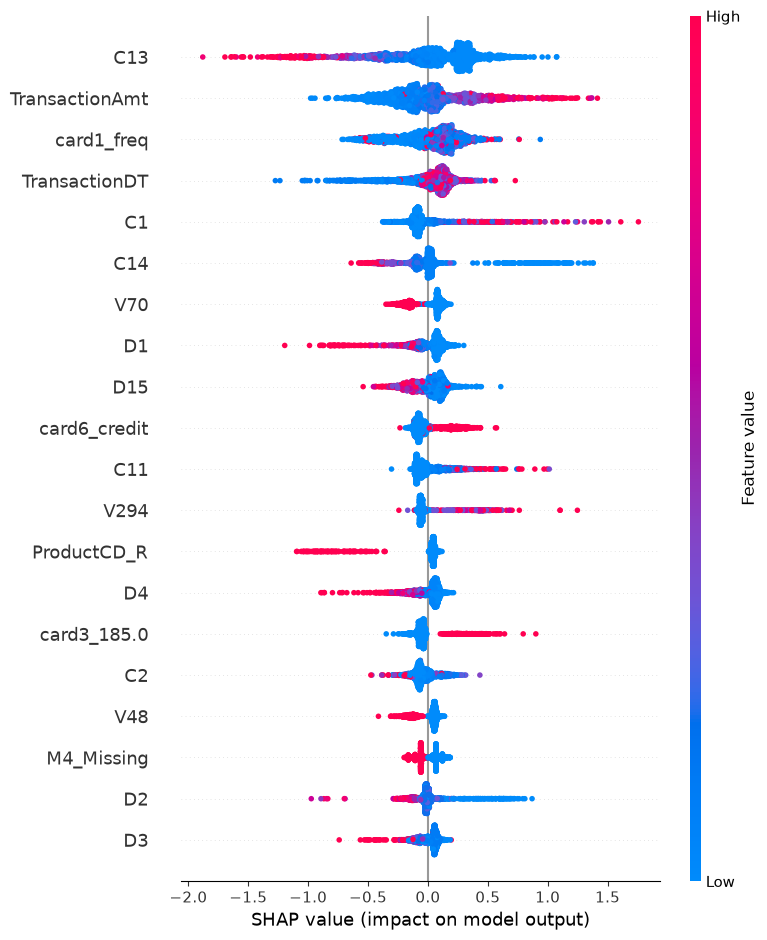

In [68]:
# --------------------------------------------------
# Phase 7.3 — SHAP summary plot
# --------------------------------------------------

print("PREPARING SHAP SUMMARY PLOT...")
print("==============================")

# Convert sparse matrices to dense only for plotting
shap_matrix_dense = shap_values_fraud.toarray()
X_shap_dense = X_shap.toarray()

print("SHAP matrix shape:", shap_matrix_dense.shape)
print("Feature matrix shape:", X_shap_dense.shape)

# Verify alignment
assert shap_matrix_dense.shape == X_shap_dense.shape
assert shap_matrix_dense.shape[1] == len(feature_names)

print()
print("SHAP SUMMARY PLOT INPUTS VERIFIED")
print("=================================")
print("Samples:", shap_matrix_dense.shape[0])
print("Features:", shap_matrix_dense.shape[1])
print("Feature names:", len(feature_names))

print()
print("GENERATING SHAP SUMMARY PLOT...")
print("==============================")

shap.summary_plot(
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    max_display=20,
    show=True
)

SHAP DEPENDENCE ANALYSIS
Feature: C13
Feature index: 16

Generating dependence plot...


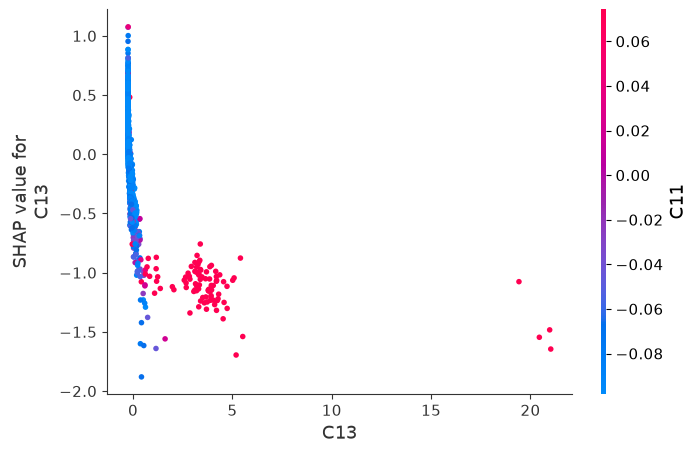

In [69]:
# --------------------------------------------------
# Phase 7.4 — SHAP dependence plot: C13
# --------------------------------------------------

print("SHAP DEPENDENCE ANALYSIS")
print("========================")

feature_to_plot = "C13"

feature_index = np.where(
    feature_names == feature_to_plot
)[0][0]

print("Feature:", feature_to_plot)
print("Feature index:", feature_index)

print()
print("Generating dependence plot...")

shap.dependence_plot(
    feature_index,
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="auto",
    show=True
)

SHAP INTERACTION ANALYSIS
Main feature: C13
Main feature index: 16
Interaction feature: C11
Interaction feature index: 14

Generating C13 × C11 dependence plot...


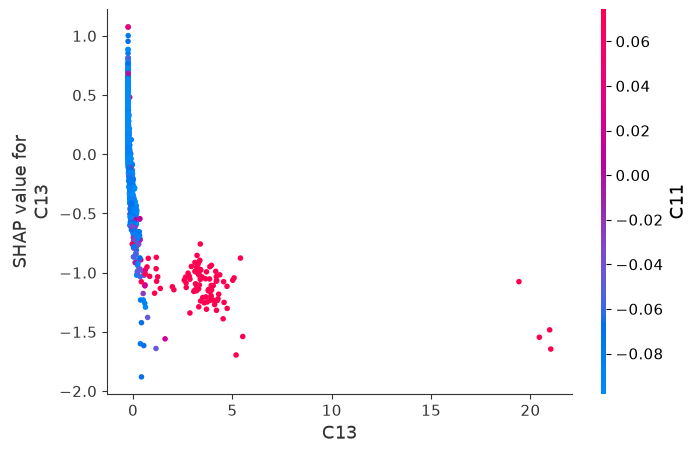

In [70]:
# --------------------------------------------------
# Phase 7.4 — SHAP C13 × C11 interaction analysis
# --------------------------------------------------

print("SHAP INTERACTION ANALYSIS")
print("=========================")

feature_to_plot = "C13"
interaction_feature = "C11"

feature_index = np.where(
    feature_names == feature_to_plot
)[0][0]

interaction_index = np.where(
    feature_names == interaction_feature
)[0][0]

print("Main feature:", feature_to_plot)
print("Main feature index:", feature_index)

print("Interaction feature:", interaction_feature)
print("Interaction feature index:", interaction_index)

print()
print("Generating C13 × C11 dependence plot...")

shap.dependence_plot(
    feature_index,
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index=interaction_feature,
    show=True
)

SHAP DEPENDENCE ANALYSIS
Feature: TransactionAmt
Feature index: 1

Generating TransactionAmt dependence plot...


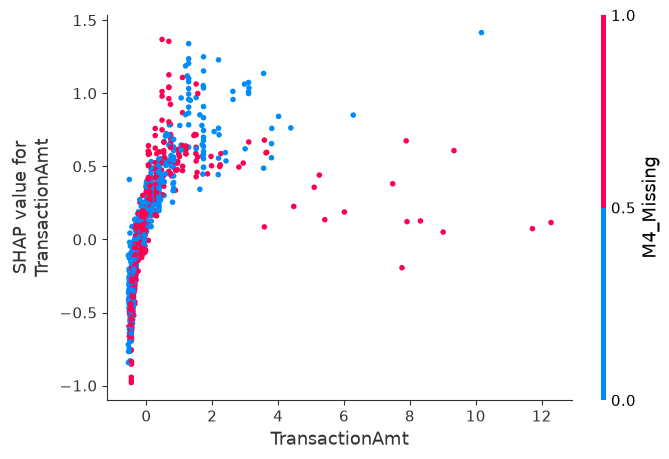

In [71]:
# --------------------------------------------------
# Phase 7.5 — SHAP dependence plot: TransactionAmt
# --------------------------------------------------

print("SHAP DEPENDENCE ANALYSIS")
print("========================")

feature_to_plot = "TransactionAmt"

feature_index = np.where(
    feature_names == feature_to_plot
)[0][0]

print("Feature:", feature_to_plot)
print("Feature index:", feature_index)

print()
print("Generating TransactionAmt dependence plot...")

shap.dependence_plot(
    feature_index,
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="auto",
    show=True
)

SHAP DEPENDENCE ANALYSIS
Feature: card1_freq
Feature index: 395

Generating card1_freq dependence plot...


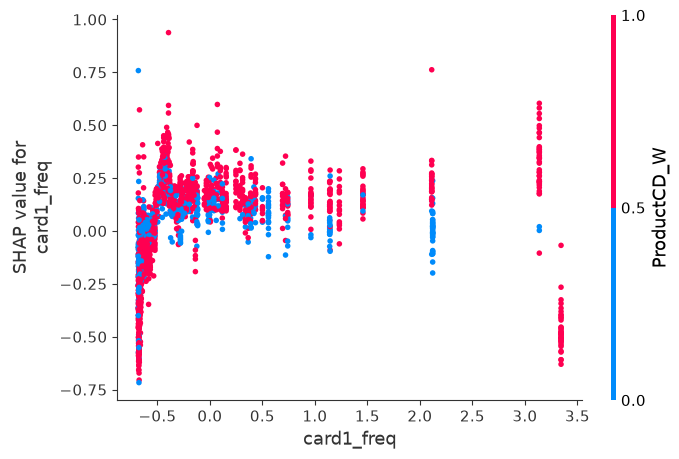

In [72]:
# --------------------------------------------------
# Phase 7.6 — SHAP dependence plot: card1_freq
# --------------------------------------------------

print("SHAP DEPENDENCE ANALYSIS")
print("========================")

feature_to_plot = "card1_freq"

feature_index = np.where(
    feature_names == feature_to_plot
)[0][0]

print("Feature:", feature_to_plot)
print("Feature index:", feature_index)

print()
print("Generating card1_freq dependence plot...")

shap.dependence_plot(
    feature_index,
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="auto",
    show=True
)

SHAP DEPENDENCE ANALYSIS
Feature: TransactionDT
Feature index: 0

Generating TransactionDT dependence plot...


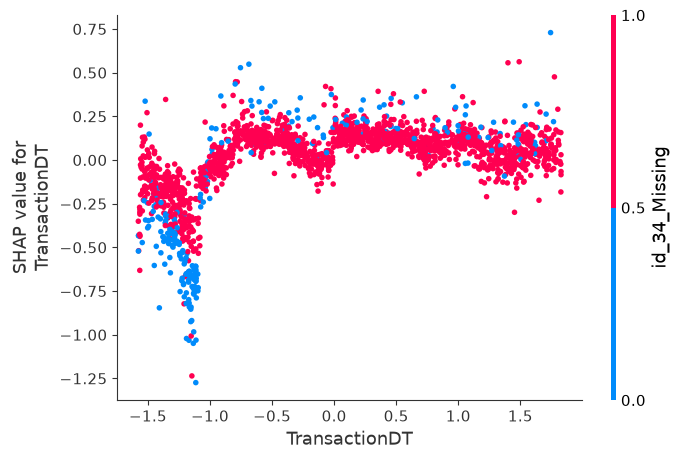

In [73]:
# --------------------------------------------------
# Phase 7.7 — SHAP dependence plot: TransactionDT
# --------------------------------------------------

print("SHAP DEPENDENCE ANALYSIS")
print("========================")

feature_to_plot = "TransactionDT"

feature_index = np.where(
    feature_names == feature_to_plot
)[0][0]

print("Feature:", feature_to_plot)
print("Feature index:", feature_index)

print()
print("Generating TransactionDT dependence plot...")

shap.dependence_plot(
    feature_index,
    shap_matrix_dense,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="auto",
    show=True
)

In [74]:
# --------------------------------------------------
# Phase 7.5 — Recover SHAP values safely
# --------------------------------------------------

import numpy as np
import scipy.sparse as sp

print("RECOVERING SHAP VALUES")
print("======================")

print("Original SHAP object type:", type(shap_values))

# --------------------------------------------------
# Extract fraud-class SHAP values
# --------------------------------------------------

if isinstance(shap_values, list):

    print("SHAP output is a list.")

    shap_values_fraud_raw = shap_values[1]

else:

    print("SHAP output is not a list.")

    shap_values_fraud_raw = shap_values

print(
    "Fraud-class SHAP type:",
    type(shap_values_fraud_raw)
)

# --------------------------------------------------
# Safely convert sparse matrix to dense NumPy array
# --------------------------------------------------

if sp.issparse(shap_values_fraud_raw):

    print("SHAP values are sparse.")
    print("Converting sparse matrix to dense...")

    shap_values_array = (
        shap_values_fraud_raw.toarray()
    )

else:

    print("SHAP values are already dense.")

    shap_values_array = np.asarray(
        shap_values_fraud_raw
    )

print()
print("FINAL SHAP ARRAY")
print("================")

print("Type:", type(shap_values_array))
print("Shape:", shap_values_array.shape)
print("Dimensions:", shap_values_array.ndim)

RECOVERING SHAP VALUES
Original SHAP object type: <class 'scipy.sparse._csr.csr_matrix'>
SHAP output is not a list.
Fraud-class SHAP type: <class 'scipy.sparse._csr.csr_matrix'>
SHAP values are sparse.
Converting sparse matrix to dense...

FINAL SHAP ARRAY
Type: <class 'numpy.ndarray'>
Shape: (2000, 2148)
Dimensions: 2


In [75]:
# --------------------------------------------------
# Verify SHAP alignment
# --------------------------------------------------

print("\nSHAP ALIGNMENT CHECK")
print("===================")

print("SHAP shape:", shap_values_array.shape)
print("Feature matrix shape:", X_shap_dense.shape)
print("Feature names:", len(feature_names))

assert shap_values_array.ndim == 2

assert (
    shap_values_array.shape
    == X_shap_dense.shape
)

assert (
    shap_values_array.shape[1]
    == len(feature_names)
)

print()
print("SHAP INPUTS VERIFIED")
print("====================")
print("Samples:", shap_values_array.shape[0])
print("Features:", shap_values_array.shape[1])
print("Feature names:", len(feature_names))


SHAP ALIGNMENT CHECK
SHAP shape: (2000, 2148)
Feature matrix shape: (2000, 2148)
Feature names: 2148

SHAP INPUTS VERIFIED
Samples: 2000
Features: 2148
Feature names: 2148


In [76]:
# --------------------------------------------------
# Phase 7.5 — SHAP interaction analysis
# --------------------------------------------------

TOP_N_FEATURES = 10

top_features = (
    shap_importance
    .head(TOP_N_FEATURES)["Feature"]
    .tolist()
)

interaction_results = []

print("\nTOP FEATURES AND THEIR STRONGEST INTERACTIONS")
print("==============================================")

for feature in top_features:

    feature_index = np.where(
        feature_names == feature
    )[0][0]

    print(f"\nAnalyzing: {feature}")

    interaction_indices = (
        shap.utils.approximate_interactions(
            feature_index,
            shap_values_array,
            X_shap_dense
        )
    )

    # Remove the feature itself if it appears
    interaction_indices = [
        idx
        for idx in interaction_indices
        if idx != feature_index
    ]

    # Top 5 interaction candidates
    top_interaction_indices = (
        interaction_indices[:5]
    )

    for rank, interaction_index in enumerate(
        top_interaction_indices,
        start=1
    ):

        interaction_feature = (
            feature_names[interaction_index]
        )

        interaction_results.append({
            "Feature": feature,
            "Interaction Feature":
                interaction_feature,
            "Rank": rank
        })

        print(
            f"{rank}. {interaction_feature}"
        )

interaction_df = pd.DataFrame(
    interaction_results
)


TOP FEATURES AND THEIR STRONGEST INTERACTIONS

Analyzing: C13
1. C11
2. C1
3. C8
4. C6
5. C10

Analyzing: TransactionAmt
1. M4_Missing
2. M6_Missing
3. ProductCD_W
4. M9_Missing
5. M8_Missing

Analyzing: card1_freq
1. ProductCD_W
2. id_12_Missing
3. V302
4. id_38_Missing
5. id_29_Missing

Analyzing: TransactionDT
1. id_34_Missing
2. id_30_Missing
3. id_35_T
4. id_33_Missing
5. id_12_Missing

Analyzing: C1
1. C8
2. V303
3. R_emaildomain_gmail.com
4. V304
5. ProductCD_W

Analyzing: C14
1. V258
2. id_12_NotFound
3. ProductCD_W
4. C7
5. id_28_Missing

Analyzing: V70
1. V131
2. V312
3. V282
4. V130
5. V283

Analyzing: D1
1. addr1_337.0
2. C8
3. C10
4. card6_debit
5. C4

Analyzing: D15
1. C5
2. C9
3. C14
4. C13
5. C11

Analyzing: card6_credit
1. D1
2. D2
3. D15
4. D10
5. D11


GENERATING C13 × C11 INTERACTION PLOT...


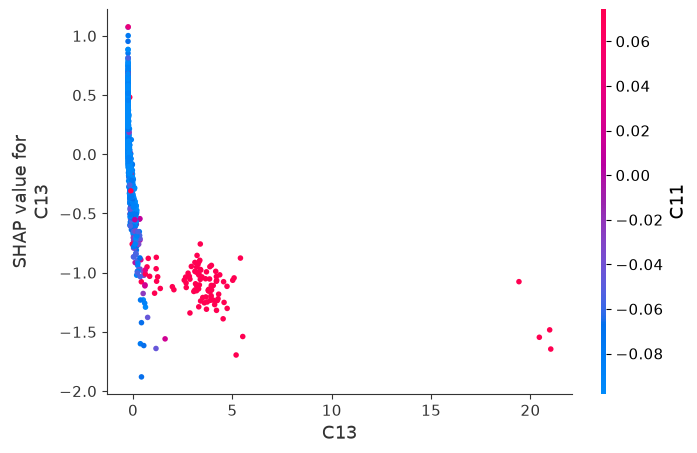

In [77]:
# --------------------------------------------------
# Phase 7.5.1 — C13 × C11 interaction
# --------------------------------------------------

print("GENERATING C13 × C11 INTERACTION PLOT...")
print("=========================================")

shap.dependence_plot(
    "C13",
    shap_values_array,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="C11",
    show=True
)

GENERATING TransactionAmt × M4_Missing PLOT...


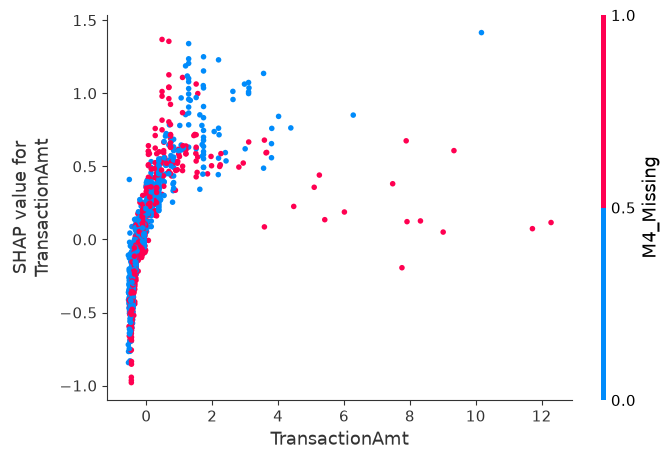

In [78]:
# --------------------------------------------------
# TransactionAmt × M4_Missing
# --------------------------------------------------

print("GENERATING TransactionAmt × M4_Missing PLOT...")
print("==============================================")

shap.dependence_plot(
    "TransactionAmt",
    shap_values_array,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="M4_Missing",
    show=True
)

GENERATING card1_freq × ProductCD_W PLOT...


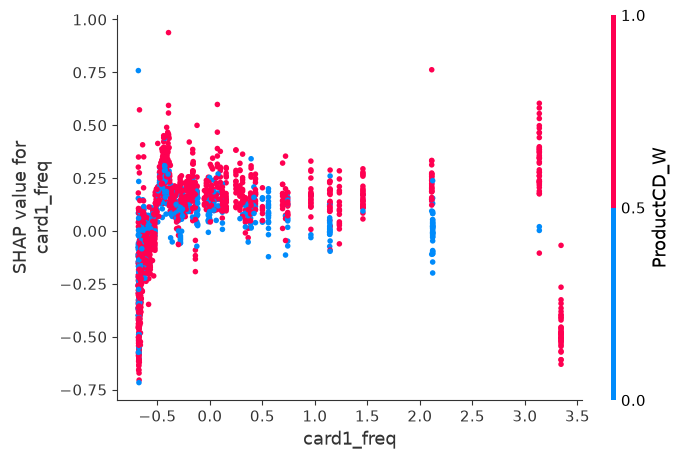

In [79]:
# --------------------------------------------------
# card1_freq × ProductCD_W
# --------------------------------------------------

print("GENERATING card1_freq × ProductCD_W PLOT...")
print("===========================================")

shap.dependence_plot(
    "card1_freq",
    shap_values_array,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="ProductCD_W",
    show=True
)

GENERATING TransactionDT × id_34_Missing PLOT...


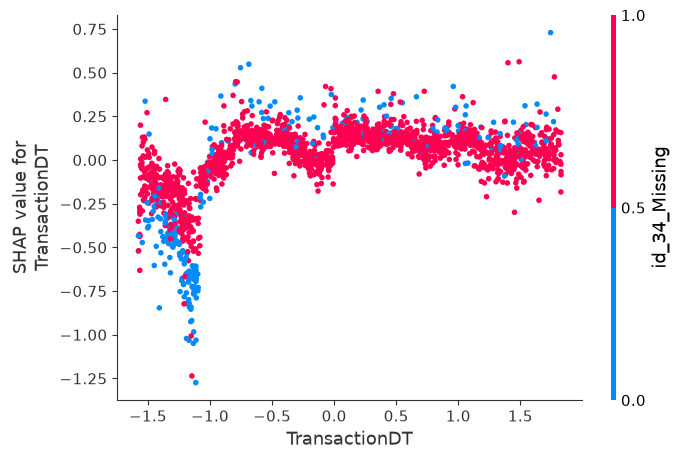

In [80]:
# --------------------------------------------------
# TransactionDT × id_34_Missing
# --------------------------------------------------

print("GENERATING TransactionDT × id_34_Missing PLOT...")
print("================================================")

shap.dependence_plot(
    "TransactionDT",
    shap_values_array,
    X_shap_dense,
    feature_names=feature_names,
    interaction_index="id_34_Missing",
    show=True
)

In [81]:
# --------------------------------------------------
# Phase 7.6.1 — Select representative SHAP cases
# --------------------------------------------------

import numpy as np

print("SELECTING REPRESENTATIVE SHAP CASES")
print("===================================")

# --------------------------------------------------
# Predictions for the 2,000-row SHAP sample
# --------------------------------------------------

y_shap_proba = (
    y_valid_proba_lgb_tuned[shap_indices]
)

y_shap_pred = (
    y_shap_proba >= BEST_THRESHOLD
).astype(int)

# --------------------------------------------------
# Actual labels for SHAP sample
# --------------------------------------------------

y_shap_actual = (
    y_valid.iloc[shap_indices].to_numpy()
)

# --------------------------------------------------
# Identify confusion-matrix categories
# --------------------------------------------------

tp_positions = np.where(
    (y_shap_actual == 1) &
    (y_shap_pred == 1)
)[0]

fn_positions = np.where(
    (y_shap_actual == 1) &
    (y_shap_pred == 0)
)[0]

fp_positions = np.where(
    (y_shap_actual == 0) &
    (y_shap_pred == 1)
)[0]

tn_positions = np.where(
    (y_shap_actual == 0) &
    (y_shap_pred == 0)
)[0]

print("SHAP SAMPLE CONFUSION CATEGORIES")
print("---------------------------------")

print("True Positives :", len(tp_positions))
print("False Negatives:", len(fn_positions))
print("False Positives:", len(fp_positions))
print("True Negatives :", len(tn_positions))

# --------------------------------------------------
# Safety checks
# --------------------------------------------------

assert len(tp_positions) > 0, "No TP cases in SHAP sample."
assert len(fn_positions) > 0, "No FN cases in SHAP sample."
assert len(fp_positions) > 0, "No FP cases in SHAP sample."
assert len(tn_positions) > 0, "No TN cases in SHAP sample."

# --------------------------------------------------
# Select representative examples
# --------------------------------------------------

# TP:
# Highest fraud probability among correctly detected fraud
tp_position = tp_positions[
    np.argmax(
        y_shap_proba[tp_positions]
    )
]

# FN:
# Highest fraud probability among missed fraud
fn_position = fn_positions[
    np.argmax(
        y_shap_proba[fn_positions]
    )
]

# FP:
# Highest fraud probability among legitimate
# transactions incorrectly classified as fraud
fp_position = fp_positions[
    np.argmax(
        y_shap_proba[fp_positions]
    )
]

# TN:
# Highest fraud probability among correctly
# classified legitimate transactions
tn_position = tn_positions[
    np.argmax(
        y_shap_proba[tn_positions]
    )
]

# --------------------------------------------------
# Convert SHAP sample positions to validation indices
# --------------------------------------------------

tp_index = int(shap_indices[tp_position])
fn_index = int(shap_indices[fn_position])
fp_index = int(shap_indices[fp_position])
tn_index = int(shap_indices[tn_position])

# --------------------------------------------------
# Display selected cases
# --------------------------------------------------

print()
print("SELECTED REPRESENTATIVE CASES")
print("=============================")

print(
    f"TP | Validation index: {tp_index:6d} | "
    f"Probability: "
    f"{y_valid_proba_lgb_tuned[tp_index]:.6f}"
)

print(
    f"FN | Validation index: {fn_index:6d} | "
    f"Probability: "
    f"{y_valid_proba_lgb_tuned[fn_index]:.6f}"
)

print(
    f"FP | Validation index: {fp_index:6d} | "
    f"Probability: "
    f"{y_valid_proba_lgb_tuned[fp_index]:.6f}"
)

print(
    f"TN | Validation index: {tn_index:6d} | "
    f"Probability: "
    f"{y_valid_proba_lgb_tuned[tn_index]:.6f}"
)

SELECTING REPRESENTATIVE SHAP CASES
SHAP SAMPLE CONFUSION CATEGORIES
---------------------------------
True Positives : 51
False Negatives: 20
False Positives: 8
True Negatives : 1921

SELECTED REPRESENTATIVE CASES
TP | Validation index:  26391 | Probability: 0.999945
FN | Validation index:   2466 | Probability: 0.222192
FP | Validation index: 115400 | Probability: 0.984537
TN | Validation index:   4805 | Probability: 0.231354


In [83]:
# --------------------------------------------------
# Phase 7.6.2 — Individual SHAP explanation helper
# --------------------------------------------------

def explain_transaction(
    validation_index,
    case_name,
    max_display=15
):

    print()
    print("=" * 60)
    print(case_name)
    print("=" * 60)

    # --------------------------------------------------
    # Basic transaction information
    # --------------------------------------------------

    actual = int(
        y_valid.iloc[validation_index]
    )

    probability = float(
        y_valid_proba_lgb_tuned[validation_index]
    )

    prediction = int(
        probability >= BEST_THRESHOLD
    )

    print(
        "Validation index:",
        validation_index
    )

    print(
        "Actual class:",
        actual
    )

    print(
        "Predicted class:",
        prediction
    )

    print(
        f"Fraud probability: {probability:.6f}"
    )

    print(
        f"Classification threshold: "
        f"{BEST_THRESHOLD:.2f}"
    )

    # --------------------------------------------------
    # Locate transaction inside SHAP sample
    # --------------------------------------------------

    shap_positions = np.where(
        shap_indices == validation_index
    )[0]

    if len(shap_positions) == 0:

        raise ValueError(
            "Validation index is not present in "
            "the SHAP sample."
        )

    shap_position = int(
        shap_positions[0]
    )

    print(
        "SHAP sample position:",
        shap_position
    )

    # --------------------------------------------------
    # Extract SHAP row correctly
    # --------------------------------------------------

    # shap_values_fraud is a sparse matrix.
    # Convert ONLY the selected row to dense.

    row_shap = shap_values_fraud[
        shap_position
    ].toarray().reshape(-1)

    # --------------------------------------------------
    # Extract corresponding transformed features
    # --------------------------------------------------

    row_features = np.asarray(
        X_shap_dense[shap_position]
    ).reshape(-1)

    # --------------------------------------------------
    # Safety checks
    # --------------------------------------------------

    print(
        "SHAP values in row:",
        len(row_shap)
    )

    print(
        "Feature values in row:",
        len(row_features)
    )

    print(
        "Feature names:",
        len(feature_names)
    )

    assert len(row_shap) == len(feature_names), (
        f"SHAP values: {len(row_shap)}, "
        f"feature names: {len(feature_names)}"
    )

    assert len(row_features) == len(feature_names), (
        f"Feature values: {len(row_features)}, "
        f"feature names: {len(feature_names)}"
    )

    # --------------------------------------------------
    # Obtain expected value
    # --------------------------------------------------

    expected_value = explainer.expected_value

    if isinstance(
        expected_value,
        (list, np.ndarray)
    ):

        expected_value = np.asarray(
            expected_value
        ).reshape(-1)

        if len(expected_value) > 1:
            expected_value = expected_value[1]
        else:
            expected_value = expected_value[0]

    expected_value = float(
        expected_value
    )

    # --------------------------------------------------
    # Create SHAP Explanation object
    # --------------------------------------------------

    explanation = shap.Explanation(
        values=row_shap,
        base_values=expected_value,
        data=row_features,
        feature_names=feature_names
    )

    # --------------------------------------------------
    # Generate waterfall plot
    # --------------------------------------------------

    shap.plots.waterfall(
        explanation,
        max_display=max_display
    )

    return explanation


TRUE POSITIVE — CORRECTLY DETECTED FRAUD
Validation index: 26391
Actual class: 1
Predicted class: 1
Fraud probability: 0.999945
Classification threshold: 0.25
SHAP sample position: 328
SHAP values in row: 2148
Feature values in row: 2148
Feature names: 2148


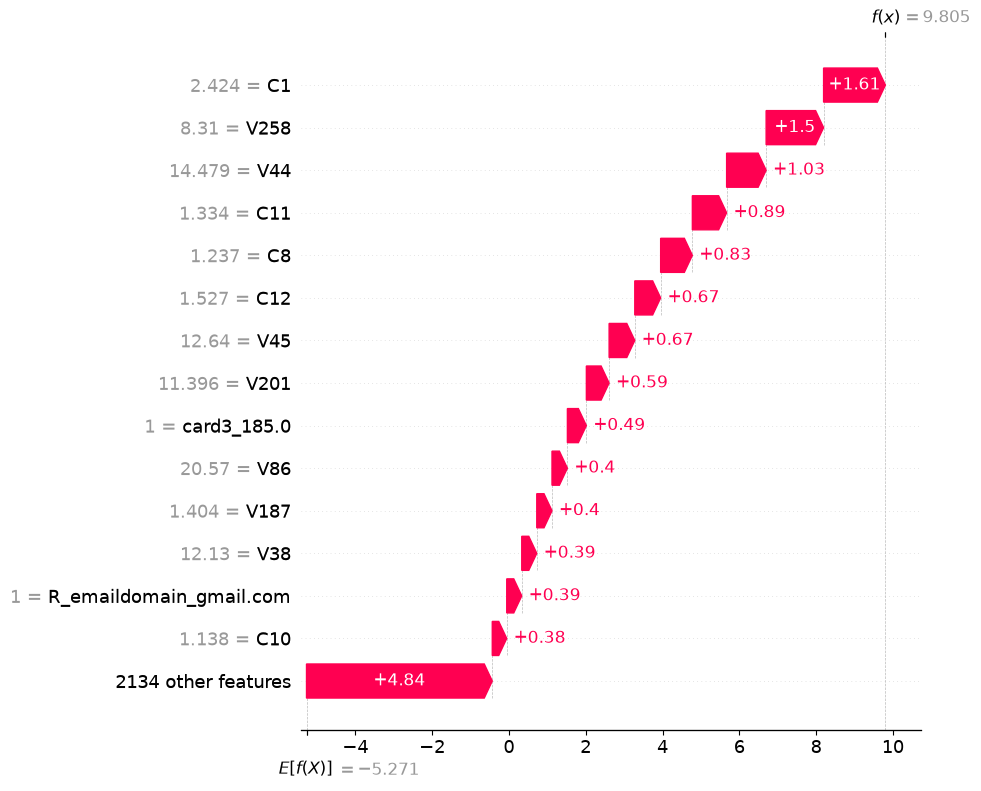

In [84]:
# --------------------------------------------------
# Phase 7.6.3a — True Positive
# --------------------------------------------------

tp_explanation = explain_transaction(
    tp_index,
    "TRUE POSITIVE — CORRECTLY DETECTED FRAUD"
)